In [1]:
import torch

# The PointNeRF rendering allocates tensors whose size depends on how many ray samples hit the
# point cloud, i.e. it differs for every sample and pose. With the default caching allocator, these
# varying sizes fragment the large block pool until cudaMalloc fails. Expandable segments avoid
# this at no runtime cost. Has to be set before torch initializes CUDA. The setting is not
# available in the original environment (PyTorch 1.12) and is silently skipped there.
try:
    torch._C._accelerator_setAllocatorSettings("expandable_segments:True")
except (AttributeError, RuntimeError):
    pass

import numpy as np

from npcd.models import NPCD
from npcd.utils import load_config, set_seed, to_torch, get_torch_model_device
from npcd.utils.vis import vis, hcat, add_box, add_label


torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

/home/schroepp/proj/miniforge3/envs/npcd/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def run_appearance_only_generation(model, autocast_ctx, seed, num, batch_size, N_rev, N_repaint, N_resample):  # Parameters N_rev, N_repaint, N_resample match Algorithm 1 in the paper
    # Generate 1 object:
    print(f"Generating 1 object with seed {seed}:")
    set_seed(seed)
    with torch.no_grad(), autocast_ctx:
        coords, feats = model.diffusion.generate(num=1, batch_size=1, progress=True)  
        # output shapes: (1, 3, num_points) and (1, feats_dim, num_points)

    # Re-sample appearance-only:
    print(f"Generating {num} objects with re-sampled appearance with seed {seed}:")
    set_seed(seed)
    with torch.no_grad(), autocast_ctx:
        coords_resampled, feats_resampled = model.diffusion.resample_appearance(coords_in=coords, num=num, batch_size=batch_size, progress=True, N_rev=N_rev, N_repaint=N_repaint, N_resample=N_resample)
        # output shapes: (num_objects, 3, num_points) and (num_objects, feats_dim, num_points)

    return coords, feats, coords_resampled, feats_resampled

def run_shape_only_generation(model, autocast_ctx, seed, num, batch_size, N_rev, N_repaint, N_resample):  # Parameters N_rev, N_repaint, N_resample match Algorithm 1 in the paper, with the roles of coords and feats swapped
    # Generate 1 object:
    print(f"Generating 1 object with seed {seed}:")
    set_seed(seed)
    with torch.no_grad(), autocast_ctx:
        coords, feats = model.diffusion.generate(num=1, batch_size=1, progress=True)  
        # output shapes: (1, 3, num_points) and (1, feats_dim, num_points)

    # Re-sample shape-only:
    print(f"Generating {num} objects with re-sampled shape with seed {seed}:")
    set_seed(seed)
    with torch.no_grad(), autocast_ctx:
        coords_resampled, feats_resampled = model.diffusion.resample_shape(feats_in=feats, num=num, batch_size=batch_size, progress=True, N_rev=N_rev, N_repaint=N_repaint, N_resample=N_resample)
        # output shapes: (num_objects, 3, num_points) and (num_objects, feats_dim, num_points)

    return coords, feats, coords_resampled, feats_resampled

def render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution):
    # Render the original object with the chosen pose and intrinsics and resolution:
    coords_for_rendering = coords[0].float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, 3)
    feats_for_rendering = feats[0].float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, feats_dim)

    with torch.no_grad():
        output = model.pointnerf.render(coords_for_rendering, feats_for_rendering, pose, intrinsics, resolution=resolution)
        image = output.channels  # shape: (batch, num_views, H*W, 3)
        image = image[0,0].transpose(0,1).reshape(3, resolution, resolution).cpu().numpy()
        image = np.clip(image, 0., 1.)
        orig_image = image

    # Render the resampled objects with the same pose and intrinsics and resolution:
    resampled_images = []
    for cur_coords_resampled, cur_feats_resampled in zip(coords_resampled, feats_resampled):
        coords_for_rendering = cur_coords_resampled.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, 3)
        feats_for_rendering = cur_feats_resampled.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, feats_dim)

        with torch.no_grad():
            output = model.pointnerf.render(coords_for_rendering, feats_for_rendering, pose, intrinsics, resolution=resolution)
            image = output.channels  # shape: (batch, num_views, H*W, 3)
            image = image[0,0].transpose(0,1).reshape(3, resolution, resolution).cpu().numpy()
            image = np.clip(image, 0., 1.)
            resampled_images.append(image)

    return orig_image, resampled_images

# SRN cars

## Setup

In [3]:
config = load_config("configs/npcd_srncars.yaml")

model = NPCD(use_flash_attn=True, **config["model"])
model.load_state_dict(torch.load("weights/npcd_srncars.pt"))
model.eval().cuda()
autocast_ctx = torch.amp.autocast('cuda', dtype=torch.float16, enabled=True)
device = get_torch_model_device(model)

# Get data and prepare for rendering:
resolution = 128  # resolution for the rendered images
pose = np.load(config["inference"]["test_poses_path"])[64]
intrinsics = np.load(config["inference"]["intrinsics_path"])[64]
pose = to_torch(pose, device=device).float()[None, None]  # (batch, num_views, 4, 4)
intrinsics = to_torch(intrinsics, device=device).float()[None, None]  # (batch, num_views, 3, 3)
intrinsics *= (resolution/128.)

## Shape-only generation

Generating 1 object with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [00:10<00:00, 94.15it/s]


Generating 8 objects with re-sampled shape with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [00:56<00:00, 17.77it/s]


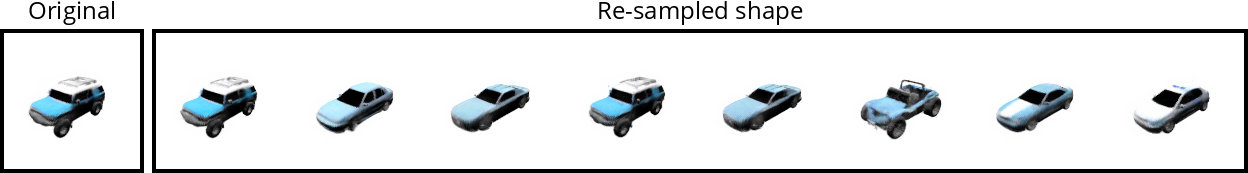

In [4]:
coords, feats, coords_resampled, feats_resampled = run_shape_only_generation(model, autocast_ctx, seed=6, num=8, batch_size=8, N_rev=50, N_repaint=0, N_resample=0)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled shape", nest_grid=True)
    ).vis()

## Appearance-only generation

Generating 1 object with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [00:10<00:00, 96.76it/s]


Generating 8 objects with re-sampled appearance with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [03:33<00:00,  4.68it/s]


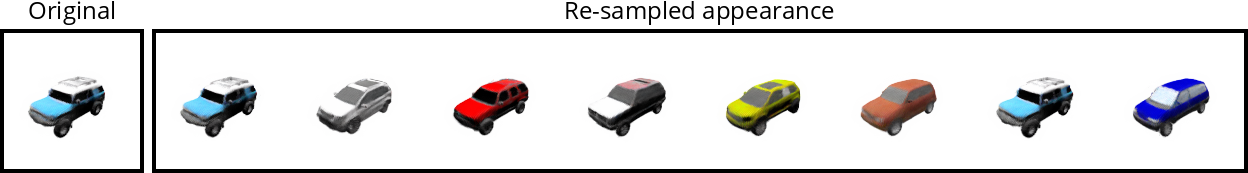

In [5]:
coords, feats, coords_resampled, feats_resampled = run_appearance_only_generation(model, autocast_ctx, seed=6, num=8, batch_size=8, N_rev=15, N_repaint=80, N_resample=40)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled appearance", nest_grid=True)
    ).vis()

# SRN chairs

## Setup

In [6]:
config = load_config("configs/npcd_srnchairs.yaml")

model = NPCD(use_flash_attn=True, **config["model"])
model.load_state_dict(torch.load("weights/npcd_srnchairs.pt"))
model.eval().cuda()
autocast_ctx = torch.amp.autocast('cuda', dtype=torch.float16, enabled=True)
device = get_torch_model_device(model)

# Get data and prepare for rendering:
resolution = 128  # resolution for the rendered images
pose = np.load(config["inference"]["test_poses_path"])[64]
intrinsics = np.load(config["inference"]["intrinsics_path"])[64]
pose = to_torch(pose, device=device).float()[None, None]  # (batch, num_views, 4, 4)
intrinsics = to_torch(intrinsics, device=device).float()[None, None]  # (batch, num_views, 3, 3)
intrinsics *= (resolution/128.)

## Appearance-only generation

Generating 1 object with seed 3:
Setting random seed to: 3


100%|██████████| 1000/1000 [00:09<00:00, 107.04it/s]


Generating 8 objects with re-sampled appearance with seed 3:
Setting random seed to: 3


100%|██████████| 1000/1000 [01:15<00:00, 13.31it/s]


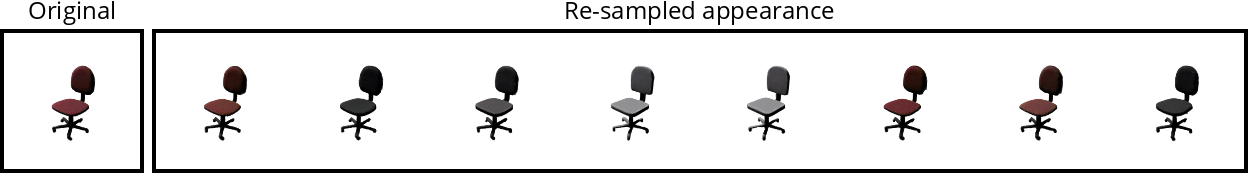

In [7]:
coords, feats, coords_resampled, feats_resampled = run_appearance_only_generation(model, autocast_ctx, seed=3, num=8, batch_size=8, N_rev=15, N_repaint=50, N_resample=10)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled appearance", nest_grid=True)
    ).vis()

## Shape-only generation

Generating 1 object with seed 3:
Setting random seed to: 3


100%|██████████| 1000/1000 [00:09<00:00, 100.38it/s]


Generating 8 objects with re-sampled shape with seed 3:
Setting random seed to: 3


100%|██████████| 1000/1000 [01:02<00:00, 16.12it/s]


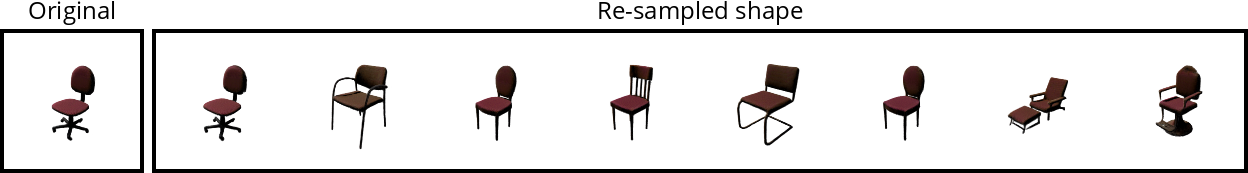

In [8]:
coords, feats, coords_resampled, feats_resampled = run_shape_only_generation(model, autocast_ctx, seed=3, num=8, batch_size=8, N_rev=50, N_repaint=100, N_resample=2)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled shape", nest_grid=True)
    ).vis()

# PhotoShape chairs

## Setup

In [9]:
config = load_config("configs/npcd_photoshapechairs.yaml")

model = NPCD(use_flash_attn=True, **config["model"])
model.load_state_dict(torch.load("weights/npcd_photoshapechairs.pt"))
model.eval().cuda()
autocast_ctx = torch.amp.autocast('cuda', dtype=torch.float16, enabled=True)
device = get_torch_model_device(model)

# Get data and prepare for rendering:
resolution = 128  # resolution for the rendered images
pose = np.load(config["inference"]["test_poses_path"])[64]
intrinsics = np.load(config["inference"]["intrinsics_path"])[64]
pose = to_torch(pose, device=device).float()[None, None]  # (batch, num_views, 4, 4)
intrinsics = to_torch(intrinsics, device=device).float()[None, None]  # (batch, num_views, 3, 3)
intrinsics *= (resolution/128.)

## Appearance-only generation

Generating 1 object with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [00:09<00:00, 107.14it/s]


Generating 8 objects with re-sampled appearance with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [01:14<00:00, 13.43it/s]


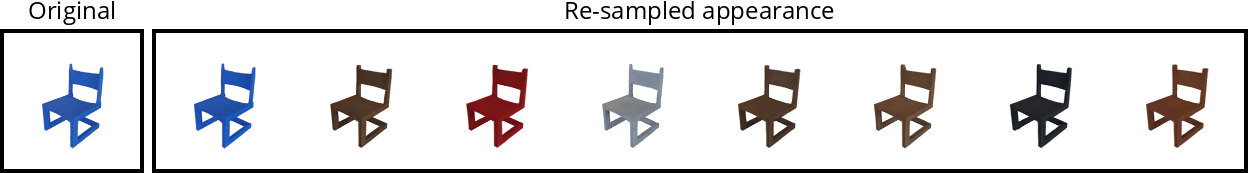

In [10]:
coords, feats, coords_resampled, feats_resampled = run_appearance_only_generation(model, autocast_ctx, seed=6, num=8, batch_size=8, N_rev=15, N_repaint=50, N_resample=10)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled appearance", nest_grid=True)
    ).vis()

## Shape-only generation

Generating 1 object with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [00:09<00:00, 100.16it/s]


Generating 8 objects with re-sampled shape with seed 6:
Setting random seed to: 6


100%|██████████| 1000/1000 [01:02<00:00, 16.11it/s]


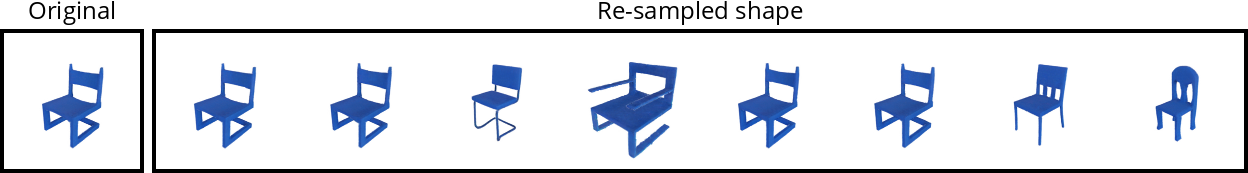

In [11]:
coords, feats, coords_resampled, feats_resampled = run_shape_only_generation(model, autocast_ctx, seed=6, num=8, batch_size=8, N_rev=50, N_repaint=100, N_resample=2)
orig_image, resampled_images = render_disentangled_generation(coords, feats, coords_resampled, feats_resampled, model, pose, intrinsics, resolution=128)

hcat(
    add_label(add_box(orig_image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1, nest_grid=True), "Original", nest_grid=True),
    add_label(add_box(hcat(*resampled_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1), nest_grid=True), "Re-sampled shape", nest_grid=True)
    ).vis()